In [28]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt 
from models.models import FrequencyAdaptationLayer, CNN, classifier
from dataloader.dataloader import data_generator
from sklearn.metrics import f1_score, accuracy_score
# from models.loss import SinkhornDistance
# from pytorch_metric_learning import losses
# from algorithms.RAINCOAT import RAINCOAT
from models.models import classifier
import umap


In [ ]:
class FD():
    def __init__(self):
        super(FD, self).__init__()
        self.sequence_len = 5120
        # self.scenarios = [("0", "1"), ("1", "2"), ("3", "1"), ("1", "0"), ("2", "3")]
        self.scenarios = [("0", "1"), ("0", "2"), ("0", "3"), ("1", "0"), ("1", "3"), ("2", "0"), ("2", "1"), ("3", "0"), ("3", "2")]
        self.class_names = ['Healthy', 'D1', 'D2']
        self.num_classes = 3
        self.shuffle = True
        self.drop_last = False
        self.normalize = True

        # Model configs
        self.input_channels = 1
        self.kernel_size = 32
        self.stride = 1
        self.dropout = 0.5

        self.mid_channels = 64
        self.final_out_channels = 128
        self.features_len = 1

        # TCN features
        self.tcn_layers = [75, 150]
        self.tcn_final_out_channles = self.tcn_layers[-1]
        self.tcn_kernel_size = 17
        self.tcn_dropout = 0.0

        # lstm features
        self.lstm_hid = 128
        self.lstm_n_layers = 1
        self.lstm_bid = False

        # discriminator
        self.disc_hid_dim = 64
        self.DSKN_disc_hid = 128
        self.hidden_dim = 500
        self.AR_hid_dim = 128
        self.fourier_modes = 64
        
        self.intra_only = True
        self.num_splits = 8

        self.AR_hid_dim_raw = self.input_channels


data_path = 'dataset/FD'
src_id = '0'
trg_id = '1'
dataset_configs = FD()
hparams = {"batch_size":64, 'learning_rate':1e-3,'weight_decay': 1e-4,'num_epochs': 100}

src_train_dl = data_generator(data_path, src_id, dataset_configs, hparams, "test")
trg_train_dl = data_generator(data_path, trg_id, dataset_configs, hparams, "test")

freq_adapter = FrequencyAdaptationLayer(
            seq_len=5120,
            channels=1,
            amp_scale=0.80482,
            phase_scale=1.69806,
            hidden_dim=64
        )
feature_extractor = CNN(FD())
Classifier = classifier(FD())
network = nn.Sequential(freq_adapter, feature_extractor, Classifier)
network.load_state_dict(torch.load(f'exp/FD/proposed/{src_id}_to_{trg_id}_run_2/checkpoint.pt')['best'])

/tmp/ipykernel_417312/2076706550.py:66: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  network.load_state_dict(torch.load(f'exp/FD/proposed/{src_id}_to_{trg_id}_run_1/checkpo

<All keys matched successfully>

Average Amplitude Distance to Source - Target: 18.0487
Average Amplitude Distance to Source - Adapted: 17.9560
Average Phase Distance to Source - Target: 0.0888 radians
Average Phase Distance to Source - Adapted: 0.0886 radians


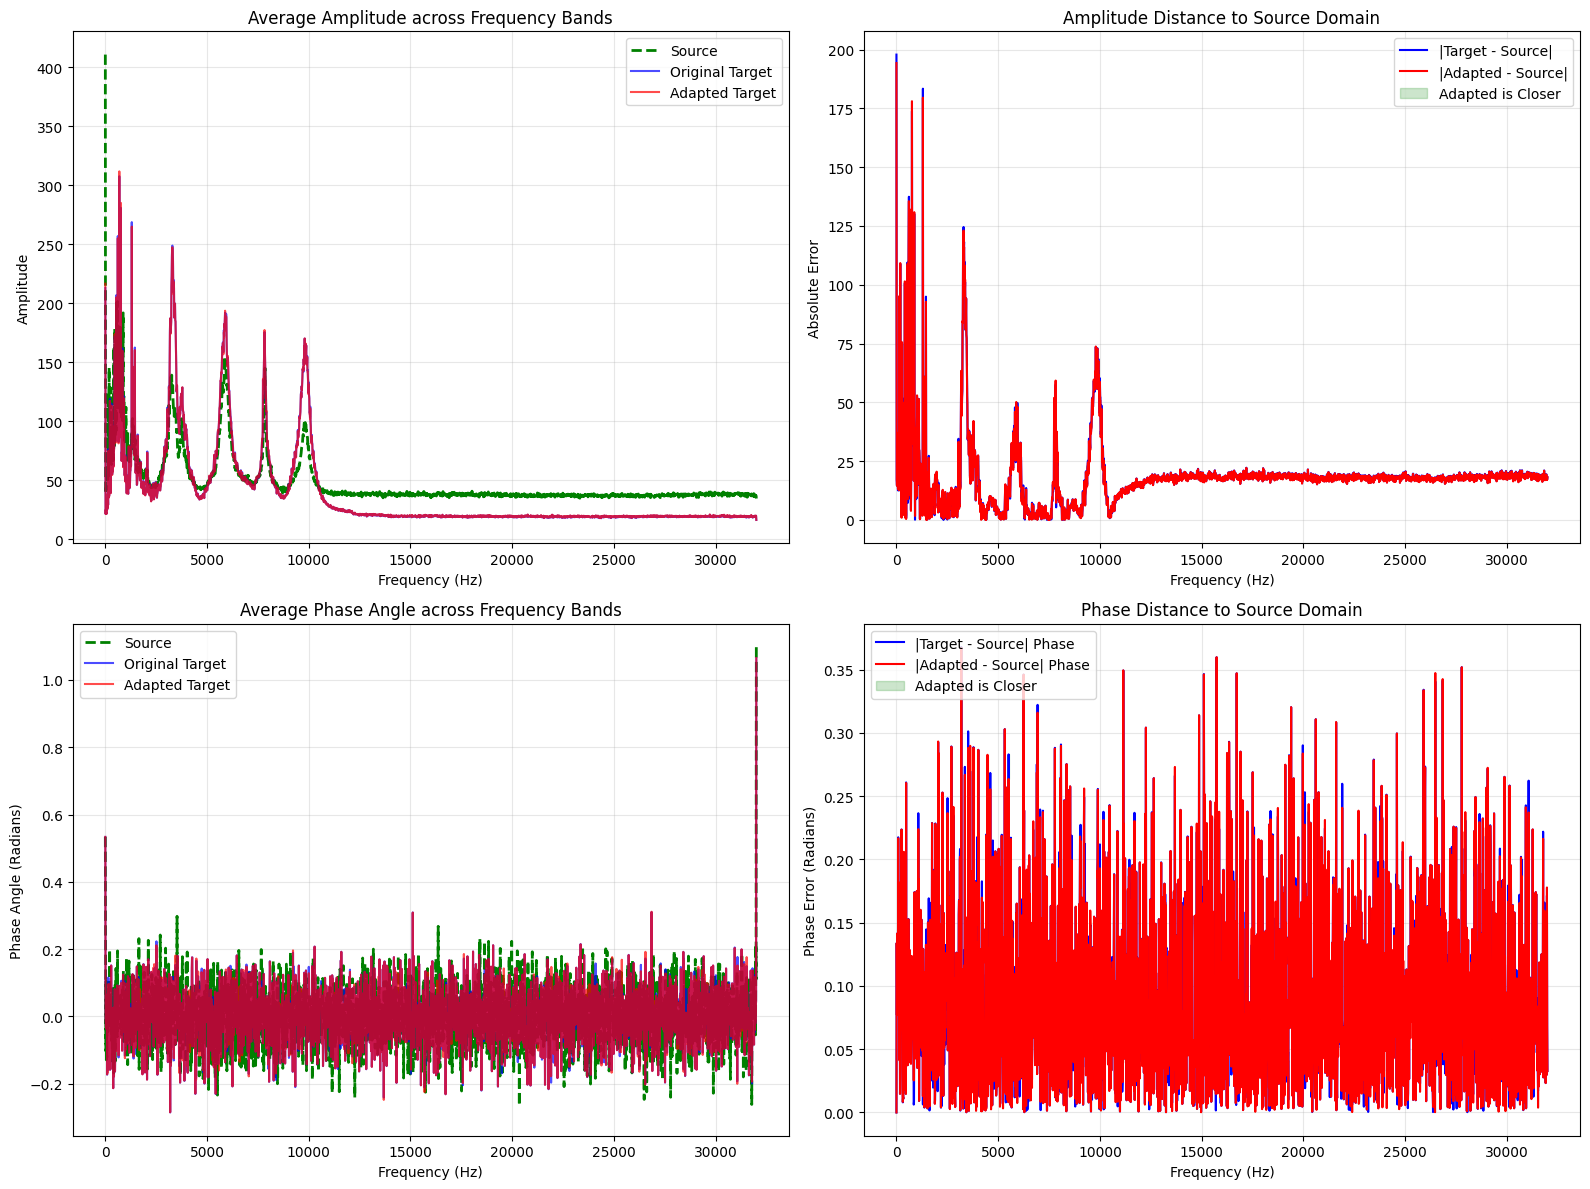

In [30]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# --- 准备存储各频段平均值的列表 ---
trg_amp_list, trg_phase_list = [], []
adap_amp_list, adap_phase_list = [], []
src_amp_list, src_phase_list = [], []

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
network.to(device)
feature_extractor.eval()
freq_adapter.eval()

with torch.no_grad():
    # 1. 收集 Target 和 Adapted 的频域特征
    for step, (trg_x, trg_y, _) in enumerate(trg_train_dl):
        trg_x = trg_x.float().to(device)
        adapted_x = freq_adapter(trg_x)
        
        # 计算 FFT
        trg_fft = torch.fft.rfft(trg_x, dim=-1)
        adap_fft = torch.fft.rfft(adapted_x, dim=-1)
        
        # 提取 幅值(Amplitude) 并跨 Batch 和 Channel 取平均 -> [Freq_len]
        trg_amp = torch.abs(trg_fft).mean(dim=(0, 1))
        adap_amp = torch.abs(adap_fft).mean(dim=(0, 1))
        
        # 提取 相角(Phase) 并跨 Batch 和 Channel 取平均 -> [Freq_len]
        trg_phase = torch.angle(trg_fft).mean(dim=(0, 1))
        adap_phase = torch.angle(adap_fft).mean(dim=(0, 1))
        
        trg_amp_list.append(trg_amp.cpu().numpy())
        adap_amp_list.append(adap_amp.cpu().numpy())
        trg_phase_list.append(trg_phase.cpu().numpy())
        adap_phase_list.append(adap_phase.cpu().numpy())
        
    # 2. 收集 Source 的频域特征
    for step, (src_x, src_y, _) in enumerate(src_train_dl):
        src_x = src_x.float().to(device)
        
        src_fft = torch.fft.rfft(src_x, dim=-1)
        
        # 提取 Source 的幅值和相角
        src_amp = torch.abs(src_fft).mean(dim=(0, 1))
        src_phase = torch.angle(src_fft).mean(dim=(0, 1))
        
        src_amp_list.append(src_amp.cpu().numpy())
        src_phase_list.append(src_phase.cpu().numpy())

# --- 计算整个数据集上的最终均值 ---
final_trg_amp = np.mean(trg_amp_list, axis=0)
final_adap_amp = np.mean(adap_amp_list, axis=0)
final_src_amp = np.mean(src_amp_list, axis=0)

final_trg_phase = np.mean(trg_phase_list, axis=0)
final_adap_phase = np.mean(adap_phase_list, axis=0)
final_src_phase = np.mean(src_phase_list, axis=0)

# --- 计算分布差异 (判断 Adapted 是否更接近 Source) ---
# 幅值差距
diff_trg_src_amp = np.abs(final_trg_amp - final_src_amp)
diff_adap_src_amp = np.abs(final_adap_amp - final_src_amp)

# 相角差距函数 (解决 2pi 缠绕问题，保证相差始终在 0 到 pi 之间)
def phase_difference(p1, p2):
    diff = p1 - p2
    diff = (diff + np.pi) % (2 * np.pi) - np.pi
    return np.abs(diff)

diff_trg_src_phase = phase_difference(final_trg_phase, final_src_phase)
diff_adap_src_phase = phase_difference(final_adap_phase, final_src_phase)

# --- 可视化画图 ---
fs = 64000  # 替换成你数据集的真实采样率
seq_len = trg_x.shape[-1]
freqs_hz = np.fft.rfftfreq(seq_len, d=1/fs)

plt.figure(figsize=(16, 12))

# ================= 图1：平均幅值分布 =================
plt.subplot(2, 2, 1)
plt.plot(freqs_hz, final_src_amp, label='Source', color='green', linestyle='--', linewidth=2)
plt.plot(freqs_hz, final_trg_amp, label='Original Target', color='blue', alpha=0.7)
plt.plot(freqs_hz, final_adap_amp, label='Adapted Target', color='red', alpha=0.7)
plt.title("Average Amplitude across Frequency Bands")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True, alpha=0.3)

# ================= 图2：幅值到 Source 的距离 =================
plt.subplot(2, 2, 2)
plt.plot(freqs_hz, diff_trg_src_amp, label='|Target - Source|', color='blue')
plt.plot(freqs_hz, diff_adap_src_amp, label='|Adapted - Source|', color='red')
# 绿色阴影部分表示 Adapted 成功减小了与 Source 的差异的频段
plt.fill_between(freqs_hz, diff_trg_src_amp, diff_adap_src_amp, 
                 where=(diff_adap_src_amp < diff_trg_src_amp), 
                 color='green', alpha=0.2, label='Adapted is Closer')
plt.title("Amplitude Distance to Source Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Absolute Error")
plt.legend()
plt.grid(True, alpha=0.3)

# ================= 图3：平均相角分布 =================
plt.subplot(2, 2, 3)
plt.plot(freqs_hz, final_src_phase, label='Source', color='green', linestyle='--', linewidth=2)
plt.plot(freqs_hz, final_trg_phase, label='Original Target', color='blue', alpha=0.7)
plt.plot(freqs_hz, final_adap_phase, label='Adapted Target', color='red', alpha=0.7)
plt.title("Average Phase Angle across Frequency Bands")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Phase Angle (Radians)")
plt.legend()
plt.grid(True, alpha=0.3)
delta_amp_target = np.mean(diff_trg_src_amp)
delta_amp_adapted = np.mean(diff_adap_src_amp)
print(f"Average Amplitude Distance to Source - Target: {delta_amp_target:.4f}")
print(f"Average Amplitude Distance to Source - Adapted: {delta_amp_adapted:.4f}")
delta_phase_target = np.mean(diff_trg_src_phase)
delta_phase_adapted = np.mean(diff_adap_src_phase)
print(f"Average Phase Distance to Source - Target: {delta_phase_target:.4f} radians")
print(f"Average Phase Distance to Source - Adapted: {delta_phase_adapted:.4f} radians")
# ================= 图4：相角到 Source 的距离 =================
plt.subplot(2, 2, 4)
plt.plot(freqs_hz, diff_trg_src_phase, label='|Target - Source| Phase', color='blue')
plt.plot(freqs_hz, diff_adap_src_phase, label='|Adapted - Source| Phase', color='red')
# 绿色阴影部分表示 Adapted 成功减小了与 Source 相角差异的频段
plt.fill_between(freqs_hz, diff_trg_src_phase, diff_adap_src_phase, 
                 where=(diff_adap_src_phase < diff_trg_src_phase), 
                 color='green', alpha=0.2, label='Adapted is Closer')
plt.title("Phase Distance to Source Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Phase Error (Radians)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import umap
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import normalized_mutual_info_score
from sklearn.cluster import KMeans

# 假设你已经运行了你上面的代码，得到了 X_orig, X_adap, X_src, Y, Y_src
# X 形状应为 [N, Features] 且为 2D 数组。如果是 3D 的，记得用 X.reshape(X.shape[0], -1) 展平

# ==========================================
# 1. 定量分析：数值指标计算
# ==========================================
print("=== 定量评估指标 ===")

# 指标 A: Silhouette Score (在 Target 域上算，看类别是否分得更开)
sil_orig = silhouette_score(X_orig, Y)
sil_adap = silhouette_score(X_adap, Y)
print(f"Target 原始特征轮廓系数 (Silhouette Score): {sil_orig:.4f}")
print(f"Target 适应后特征轮廓系数 (Silhouette Score): {sil_adap:.4f}")
print(f"提升幅度: {sil_adap - sil_orig:+.4f}\n")

print("=== 定量指标：NMI (标准化互信息) ===")

# 1. 获取类别的真实数量 K
n_classes = len(np.unique(Y))

# 2. 对 Original Target Features 进行 K-Means 聚类
kmeans_orig = KMeans(n_clusters=n_classes, random_state=42, n_init=10)
cluster_labels_orig = kmeans_orig.fit_predict(X_orig) # 得到无监督聚类标签

# 3. 对 Adapted Target Features 进行 K-Means 聚类
kmeans_adap = KMeans(n_clusters=n_classes, random_state=42, n_init=10)
cluster_labels_adap = kmeans_adap.fit_predict(X_adap)

# 4. 计算 NMI
nmi_orig = normalized_mutual_info_score(Y, cluster_labels_orig)
nmi_adap = normalized_mutual_info_score(Y, cluster_labels_adap)

print(f"Target 原始特征 NMI 分数: {nmi_orig:.4f}")
print(f"Target 适应后特征 NMI 分数: {nmi_adap:.4f}")
print(f"NMI 提升幅度: {nmi_adap - nmi_orig:+.4f}\n")

# ==========================================
# 2. 定性分析：UMAP 降维可视化
# ==========================================
print("=== 正在计算 UMAP 降维 (可能需要几十秒) ===")
# 固定 random_state 以保证每次画图的结果一致
reducer = umap.UMAP(n_components=2, random_state=42)

# 将 original 和 adapted 拼在一起做降维，保证它们映射在同一个 2D 坐标系中方便对比
X_combined = np.concatenate([X_orig, X_adap], axis=0)
X_combined_2d = reducer.fit_transform(X_combined)

# 拆分回原来的两份
split_idx = X_orig.shape[0]
X_orig_2d = X_combined_2d[:split_idx]
X_adap_2d = X_combined_2d[split_idx:]

# 开始画图
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 获取类别的数量，用于分配颜色
classes = np.unique(Y)
cmap = plt.get_cmap('tab10') # 支持最多 10 个类别，类别更多请换 'tab20'

# 图1：Original Target Features
for cls in classes:
    idx = (Y == cls)
    axes[0].scatter(X_orig_2d[idx, 0], X_orig_2d[idx, 1], 
                    label=f'Class {cls}', alpha=0.7, s=15, c=[cmap(cls % 10)])
axes[0].set_title(f'Original Target Features\nSilhouette: {sil_orig:.3f}')
axes[0].axis('off') # 隐藏坐标轴，使得图看起来更干净

# 图2：Adapted Target Features
for cls in classes:
    idx = (Y == cls)
    axes[1].scatter(X_adap_2d[idx, 0], X_adap_2d[idx, 1], 
                    label=f'Class {cls}', alpha=0.7, s=15, c=[cmap(cls % 10)])
axes[1].set_title(f'Adapted Target Features\nSilhouette: {sil_adap:.3f}')
axes[1].axis('off')

# 添加图例
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(classes), bbox_to_anchor=(0.5, -0.05))

plt.suptitle("Feature Space Visualization (UMAP): Before vs. After Adaptation", fontsize=16)
plt.tight_layout()
plt.show()

=== 定量评估指标 ===


NameError: name 'X_orig' is not defined